Лабораторная работа №1
Вариант 9. Анализ данных Melbourne Housing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Общее задание 1
# Загрузка датасета
df = pd.read_csv("Melbourne_housing.csv")

print("Датасет успешно загружен!")
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Датасет успешно загружен!
Количество строк: 34857
Количество столбцов: 22


/tmp/ipykernel_1206/1791526818.py:2: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Melbourne_housing.csv")


In [ ]:
# Общее задание 2
# Исследовательский анализ данных

# 1. Типы данных
print("ТИПЫ ДАННЫХ")
print("-" * 40)
print(df.dtypes)

# 2. Количество пропущенных значений
print("\nПРОПУЩЕННЫЕ ЗНАЧЕНИЯ")
print("-" * 40)

missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

print(missing_values)

# 3. Основные статистические показатели
print("\nОСНОВНЫЕ СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ")
print("-" * 40)

statistics = df.select_dtypes(include=np.number).agg(["mean", "median", "std"])

display(statistics)

ТИПЫ ДАННЫХ
----------------------------------------
Suburb            object
Address           object
Rooms              int64
Type              object
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom          float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea      object
YearBuilt        float64
CouncilArea       object
Latitude         float64
Longtitude       float64
Regionname        object
Propertycount    float64
ParkingArea       object
Price            float64
dtype: object

ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ
----------------------------------------
Distance             1
Postcode             1
Bedroom           8217
Bathroom          8226
Car               8728
Landsize         11810
BuildingArea     21097
YearBuilt        19306
CouncilArea          3
Latitude          7976
Longtitude        7976
Propertycount        3
Price             7610
dtype: int64

ОСНОВНЫ

,Rooms,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,YearBuilt,Latitude,Longtitude,Propertycount,Price
mean,3.031012,11.184929,3116.062859,3.084647,1.624798,1.728845,593.598993,1965.289885,-37.810634,145.001851,7572.888306,1.050173e+06
median,3.000000,10.300000,3103.000000,3.000000,2.000000,2.000000,521.000000,1970.000000,-37.807600,145.007800,6763.000000,8.700000e+05
std,0.969933,6.788892,109.023903,0.980690,0.724212,1.010771,3398.841946,37.328178,0.090279,0.120169,4428.090313,6.414671e+05


In [ ]:
# Общее задание 3
# 1 задание
# Обработка пропущенных значений

# Находим столбец с наибольшим количеством пропусков
column_with_most_missing = df.isnull().sum().idxmax()
missing_count = df[column_with_most_missing].isnull().sum()

print("Столбец с наибольшим количеством пропусков:")
print(column_with_most_missing)
print("Количество пропусков:", missing_count)

# Удаляем этот столбец
df = df.drop(columns=[column_with_most_missing])

print("\nУдалён столбец:", column_with_most_missing)
print("Количество столбцов после удаления:", df.shape[1])

# 2 задание
# Удаляем строки без значения Price
rows_before = df.shape[0]

df = df.dropna(subset=["Price"])

rows_after = df.shape[0]

print("\nОбработка пропусков в Price:")
print("Строк до удаления:", rows_before)
print("Удалено строк:", rows_before - rows_after)
print("Строк после удаления:", rows_after)

Столбец с наибольшим количеством пропусков:
BuildingArea
Количество пропусков: 21097

Удалён столбец: BuildingArea
Количество столбцов после удаления: 21

Обработка пропусков в Price:
Строк до удаления: 34857
Удалено строк: 7610
Строк после удаления: 27247


In [ ]:
# Сохраняем исходные значения Price
# для построения диаграммы рассеяния

price_original = df["Price"].copy()

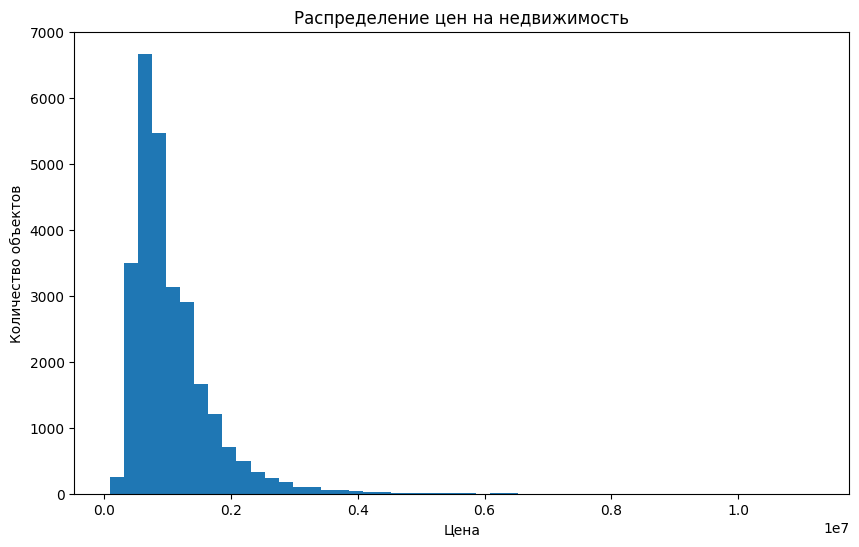

In [ ]:
# Общее задание 6
# 3 задание
# Гистограмма распределения цен на недвижимость

plt.figure(figsize=(10, 6))

plt.hist(df["Price"], bins=50)

plt.title("Распределение цен на недвижимость")
plt.xlabel("Цена")
plt.ylabel("Количество объектов")

plt.show()

In [ ]:
# 4 задание
# Средняя цена дома для 5 самых популярных пригородов

# Находим 5 самых часто встречающихся пригородов
top_5_suburbs = df["Suburb"].value_counts().head(5)

print("5 самых популярных пригородов:")
display(top_5_suburbs)

# Рассчитываем среднюю цену для этих пригородов
average_price_top_5 = (
    df[df["Suburb"].isin(top_5_suburbs.index)]
    .groupby("Suburb")["Price"]
    .mean()
)

print("Средняя цена дома:")
display(average_price_top_5)

5 самых популярных пригородов:


,count
Suburb,
Reservoir,727
Bentleigh East,493
Richmond,439
Preston,415
Brunswick,387


Средняя цена дома:


,Price
Suburb,
Bentleigh East,1.131418e+06
Brunswick,9.779888e+05
Preston,8.778699e+05
Reservoir,6.911045e+05
Richmond,1.067585e+06


In [ ]:
# Индивидуальное задание 5
# Создание нового признака PropertyAge

# Приводим YearBuilt к числовому типу
df["YearBuilt"] = pd.to_numeric(df["YearBuilt"], errors="coerce")

# Рассчитываем возраст недвижимости
current_year = 2026
df["PropertyAge"] = current_year - df["YearBuilt"]

print("Признак PropertyAge успешно создан.")
print("Количество значений PropertyAge:", df["PropertyAge"].notna().sum())

Признак PropertyAge успешно создан.
Количество значений PropertyAge: 12084


In [ ]:
# Общее задание 4
# 6 задание
# One-Hot Encoding признака Type

# Преобразуем Type в отдельные числовые признаки
df = pd.get_dummies(
    df,
    columns=["Type"],
    prefix="Type",
    dtype=int
)

print("One-Hot Encoding выполнен.")
print("Новые признаки Type:")
print([column for column in df.columns if column.startswith("Type_")])

One-Hot Encoding выполнен.
Новые признаки Type:
['Type_h', 'Type_t', 'Type_u']


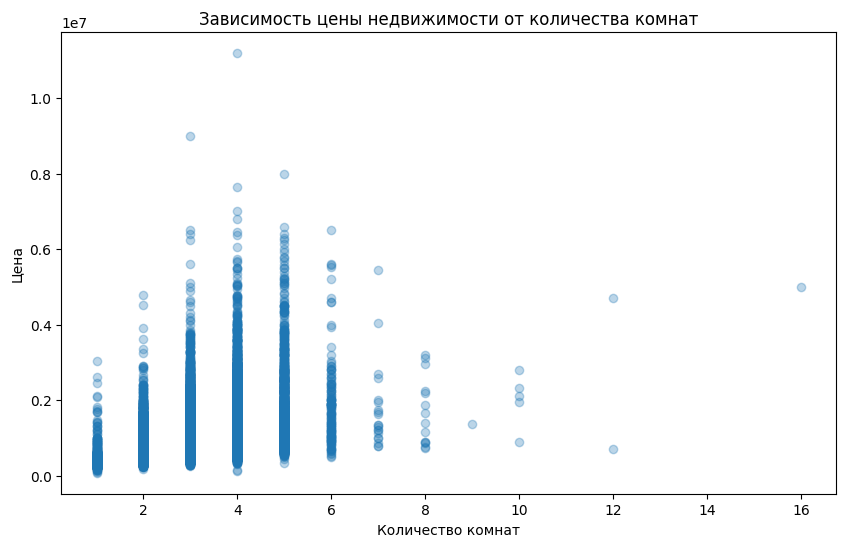

In [ ]:
# 6 задание
# Диаграмма рассеяния
# Зависимость цены недвижимости от количества комнат

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Rooms"],
    price_original,
    alpha=0.3
)

plt.title("Зависимость цены недвижимости от количества комнат")
plt.xlabel("Количество комнат")
plt.ylabel("Цена")

plt.show()

In [ ]:
# Общее задание 5
# Стандартизация числовых признаков

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = (
    df[numeric_columns] - df[numeric_columns].mean()
) / df[numeric_columns].std()

print("Стандартизация числовых признаков выполнена.")
print("Количество стандартизированных признаков:", len(numeric_columns))

Стандартизация числовых признаков выполнена.
Количество стандартизированных признаков: 16
